In [ ]:
# Semiconductor Wafer Pattern Classification
## Custom CNN Model

This notebook implements a Custom Convolutional Neural Network
for classifying wafer defect patterns using the WM-811K dataset.

### Objectives
- Load the prepared dataset splits.
- Perform wafer image preprocessing.
- Build the Custom CNN architecture.
- Train and validate the model.
- Evaluate classification performance.

In [3]:
# ==========================================
# STEP 1: IMPORT LIBRARIES AND CONNECT DRIVE
# ==========================================

# Import numerical and data handling libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import PyTorch libraries
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Import class-weight calculation utility
from sklearn.utils.class_weight import compute_class_weight

# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Check GPU availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [1]:
# ==========================================
# RECONNECT GOOGLE DRIVE
# ==========================================

from google.colab import drive

# Force a fresh Google Drive mount
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
# ==========================================
# STEP 2: DEFINE PROJECT PATHS
# ==========================================

# Define the main project directory in Google Drive
project_path = '/content/drive/MyDrive/Wafer Classification'

# Define paths for dataset, splits, and model checkpoints
dataset_path = os.path.join(project_path, 'LSWMD.pkl')
split_path = os.path.join(project_path, 'splits')
checkpoint_path = os.path.join(project_path, 'checkpoints')

# Create checkpoint directory if it does not exist
os.makedirs(checkpoint_path, exist_ok=True)

# Verify that all required files are available
print("Dataset exists:", os.path.exists(dataset_path))
print("Training split exists:", os.path.exists(
    os.path.join(split_path, 'train.csv')
))
print("Validation split exists:", os.path.exists(
    os.path.join(split_path, 'validation.csv')
))
print("Testing split exists:", os.path.exists(
    os.path.join(split_path, 'test.csv')
))

Dataset exists: True
Training split exists: True
Validation split exists: True
Testing split exists: True


In [5]:
# ==========================================
# STEP 3: LOAD TRAINING, VALIDATION AND TEST SPLITS
# ==========================================

# Read the three CSV files saved during preprocessing
train_df = pd.read_csv(os.path.join(split_path, 'train.csv'))
val_df = pd.read_csv(os.path.join(split_path, 'validation.csv'))
test_df = pd.read_csv(os.path.join(split_path, 'test.csv'))

# Display the number of samples in each split
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

# Display the first five training records
print("\nTraining split preview:")
print(train_df.head())

Training samples: 120979
Validation samples: 26116
Testing samples: 25855

Training split preview:
   row_index lotName  label_id label
0         50    lot3         8  none
1         51    lot3         8  none
2         52    lot3         8  none
3         53    lot3         8  none
4         54    lot3         8  none


In [6]:
# ==========================================
# STEP 4: LOAD ORIGINAL WM-811K DATASET
# ==========================================

# Load the original pickle dataset from Google Drive
df = pd.read_pickle(dataset_path)

# Display the dataset dimensions
print("Original dataset shape:", df.shape)

# Display available columns
print("\nDataset columns:")
print(df.columns.tolist())

Original dataset shape: (811457, 6)

Dataset columns:
['waferMap', 'dieSize', 'lotName', 'waferIndex', 'trianTestLabel', 'failureType']


In [7]:
# ==========================================
# STEP 5: EXTRACT LABELLED WAFER SAMPLES
# ==========================================

# Extract labels from the failureType column
# Each failureType entry contains a nested NumPy array

def extract_label(x):

    # Convert the entry into a NumPy array
    arr = np.asarray(x).flatten()

    # Return Unknown if the entry is empty
    if arr.size == 0:
        return "Unknown"

    # Extract the actual defect class
    return str(arr[0])


# Extract labels for all original dataset records
labels = df['failureType'].apply(extract_label)

# Remove records without defect labels
df_labeled = df[labels != "Unknown"].copy()

# Keep only labels corresponding to labelled records
labels_labeled = labels[labels != "Unknown"].copy()

# Display labelled dataset information
print("Labelled dataset shape:", df_labeled.shape)
print("Number of labelled samples:", len(labels_labeled))

# Display the nine defect classes
print("\nDefect classes:")
print(sorted(labels_labeled.unique()))

Labelled dataset shape: (172950, 6)
Number of labelled samples: 172950

Defect classes:
['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-full', 'Random', 'Scratch', 'none']


In [8]:
# ==========================================
# STEP 6: VERIFY SAVED SPLIT INDICES
# ==========================================

# Check whether every saved row index exists in df_labeled
print("Training indices valid:",
      train_df['row_index'].isin(df_labeled.index).all())

print("Validation indices valid:",
      val_df['row_index'].isin(df_labeled.index).all())

print("Testing indices valid:",
      test_df['row_index'].isin(df_labeled.index).all())

# Verify that the saved labels match the original dataset labels
print("\nTraining labels match:",
      (train_df['label'].values ==
       labels_labeled.loc[train_df['row_index']].values).all())

Training indices valid: True
Validation indices valid: True
Testing indices valid: True

Training labels match: True


In [9]:
# ==========================================
# STEP 7: DEFINE WAFER IMAGE PREPROCESSING
# ==========================================

from PIL import Image

def preprocess_wafer(wafer, target_size=64):

    # Get the original wafer-map dimensions
    height, width = wafer.shape

    # Calculate scaling factor while preserving aspect ratio
    scale = min(target_size / height, target_size / width)

    # Calculate resized dimensions
    new_height = max(1, round(height * scale))
    new_width = max(1, round(width * scale))

    # Convert wafer map into an image
    image = Image.fromarray(wafer.astype(np.uint8))

    # Resize using nearest-neighbour interpolation
    resized = image.resize(
        (new_width, new_height),
        Image.Resampling.NEAREST
    )

    # Convert resized image back to NumPy array
    resized = np.array(resized)

    # Create a zero-filled 64 x 64 canvas
    canvas = np.zeros(
        (target_size, target_size),
        dtype=np.uint8
    )

    # Calculate padding to centre the wafer map
    top = (target_size - new_height) // 2
    left = (target_size - new_width) // 2

    # Place resized wafer map in the centre
    canvas[
        top:top + new_height,
        left:left + new_width
    ] = resized

    return canvas


print("Wafer preprocessing function created successfully!")

Wafer preprocessing function created successfully!


In [10]:
# ==========================================
# STEP 8: PREPROCESS DATASET SPLITS
# ==========================================

def preprocess_dataset(split_dataframe):

    # Store all processed wafer images
    images = []

    # Retrieve each wafer using its original DataFrame index
    for i, row_index in enumerate(split_dataframe['row_index']):

        # Get the original wafer map
        wafer = df_labeled.loc[row_index, 'waferMap']

        # Resize and pad the wafer map to 64 x 64
        processed = preprocess_wafer(wafer)

        # Add the processed image to the list
        images.append(processed)

        # Display progress after every 10,000 images
        if (i + 1) % 10000 == 0:
            print(f"Processed: {i + 1} / {len(split_dataframe)}")

    # Convert the list of images into a NumPy array
    return np.stack(images)

In [11]:
# ==========================================
# STEP 9: GENERATE PREPROCESSED IMAGE ARRAYS
# ==========================================

# Preprocess training wafer maps
X_train = preprocess_dataset(train_df)

# Preprocess validation wafer maps
X_val = preprocess_dataset(val_df)

# Preprocess testing wafer maps
X_test = preprocess_dataset(test_df)

# Display the resulting array dimensions
print("\nPreprocessing completed!")

print("Training images:", X_train.shape)
print("Validation images:", X_val.shape)
print("Testing images:", X_test.shape)

print("\nData type:", X_train.dtype)

Processed: 10000 / 120979
Processed: 20000 / 120979
Processed: 30000 / 120979
Processed: 40000 / 120979
Processed: 50000 / 120979
Processed: 60000 / 120979
Processed: 70000 / 120979
Processed: 80000 / 120979
Processed: 90000 / 120979
Processed: 100000 / 120979
Processed: 110000 / 120979
Processed: 120000 / 120979
Processed: 10000 / 26116
Processed: 20000 / 26116
Processed: 10000 / 25855
Processed: 20000 / 25855

Preprocessing completed!
Training images: (120979, 64, 64)
Validation images: (26116, 64, 64)
Testing images: (25855, 64, 64)

Data type: uint8


In [12]:
# ==========================================
# STEP 10: CREATE TRAINING, VALIDATION AND TEST LABELS
# ==========================================

# Define the nine defect classes in a fixed order
class_names = sorted(labels_labeled.unique())

# Create a mapping from defect names to numerical IDs
class_to_id = {
    name: idx for idx, name in enumerate(class_names)
}

# Convert defect labels into numerical values
y_train = train_df['label'].map(class_to_id).values
y_val = val_df['label'].map(class_to_id).values
y_test = test_df['label'].map(class_to_id).values

# Display the label dimensions
print("Class mapping:")
print(class_to_id)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

# Check whether any labels are missing
print("\nMissing training labels:", pd.isna(y_train).sum())
print("Missing validation labels:", pd.isna(y_val).sum())
print("Missing testing labels:", pd.isna(y_test).sum())

Class mapping:
{'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Near-full': 5, 'Random': 6, 'Scratch': 7, 'none': 8}

Training labels: (120979,)
Validation labels: (26116,)
Testing labels: (25855,)

Missing training labels: 0
Missing validation labels: 0
Missing testing labels: 0


In [13]:
# ==========================================
# STEP 11: CALCULATE CLASS WEIGHTS
# ==========================================

# Calculate balanced weights using training labels only
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Convert weights into a PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

# Display the calculated class weights
print("Updated class weights:\n")

for name, weight in zip(class_names, class_weights):
    print(f"{name}: {weight.item():.4f}")

Updated class weights:

Center: 4.4688
Donut: 36.7271
Edge-Loc: 3.7031
Edge-Ring: 1.9564
Loc: 5.5753
Near-full: 125.6272
Random: 21.8927
Scratch: 15.4330
none: 0.1304


In [14]:
# ==========================================
# STEP 12: VERIFY DATASET DIMENSIONS
# ==========================================

# Check whether image and label counts match
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Check the image dimensions
assert X_train.shape[1:] == (64, 64)
assert X_val.shape[1:] == (64, 64)
assert X_test.shape[1:] == (64, 64)

# Check that labels belong to the nine classes
assert set(np.unique(y_train)).issubset(set(range(9)))
assert set(np.unique(y_val)).issubset(set(range(9)))
assert set(np.unique(y_test)).issubset(set(range(9)))

print("All dataset verification checks passed!")
print("Images and labels are correctly aligned.")

All dataset verification checks passed!
Images and labels are correctly aligned.


In [15]:
# ==========================================
# STEP 13: CREATE PYTORCH WAFER DATASET CLASS
# ==========================================

# Import PyTorch dataset utilities
from torch.utils.data import Dataset

class WaferDataset(Dataset):

    # Initialize the dataset with images and labels
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    # Return the total number of samples
    def __len__(self):
        return len(self.labels)

    # Retrieve one wafer image and its corresponding label
    def __getitem__(self, index):

        # Get the wafer image
        image = self.images[index]

        # Convert categorical wafer values into one-hot channels
        image = torch.tensor(image, dtype=torch.long)
        image = torch.nn.functional.one_hot(image, num_classes=3)

        # Change dimensions from (64, 64, 3) to (3, 64, 64)
        image = image.permute(2, 0, 1).float()

        # Retrieve the corresponding class label
        label = torch.tensor(self.labels[index], dtype=torch.long)

        return image, label


print("WaferDataset class created successfully!")

WaferDataset class created successfully!


In [16]:
# ==========================================
# STEP 14: CREATE DATASET OBJECTS
# ==========================================

# Create separate Dataset objects for each split
train_dataset = WaferDataset(X_train, y_train)
val_dataset = WaferDataset(X_val, y_val)
test_dataset = WaferDataset(X_test, y_test)

# Display the number of samples in each dataset
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 120979
Validation dataset: 26116
Testing dataset: 25855


In [17]:
# ==========================================
# STEP 15: CREATE PYTORCH DATALOADERS
# ==========================================

# Define batch size
BATCH_SIZE = 128

# Create training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# Create validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Create testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Display the number of batches
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 946
Validation batches: 205
Testing batches: 202


In [18]:
# ==========================================
# STEP 16: VERIFY DATALOADER OUTPUT
# ==========================================

# Retrieve one batch from the training DataLoader
images, labels = next(iter(train_loader))

# Display batch dimensions and data types
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

# Display unique pixel values and class labels
print("Unique pixel values:", torch.unique(images))
print("Unique class labels:", torch.unique(labels))

Image batch shape: torch.Size([128, 3, 64, 64])
Label batch shape: torch.Size([128])
Image data type: torch.float32
Label data type: torch.int64
Unique pixel values: tensor([0., 1.])
Unique class labels: tensor([0, 1, 2, 3, 4, 6, 7, 8])


In [19]:
# ==========================================
# STEP 17: DEFINE CUSTOM CNN ARCHITECTURE
# ==========================================

class CustomCNN(nn.Module):

    def __init__(self, num_classes=9):
        super(CustomCNN, self).__init__()

        # First convolution block: 3 input channels -> 32 feature maps
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Second convolution block: 32 -> 64 feature maps
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Third convolution block: 64 -> 128 feature maps
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convert feature maps into a single 1 x 1 representation
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification layer
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        # Extract features through convolution blocks
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        # Apply global average pooling
        x = self.global_pool(x)

        # Predict the wafer defect class
        x = self.classifier(x)

        return x


print("Custom CNN architecture created successfully!")

Custom CNN architecture created successfully!


In [20]:
# ==========================================
# STEP 18: INITIALIZE AND VERIFY CUSTOM CNN
# ==========================================

# Create the Custom CNN model
model = CustomCNN(num_classes=9).to(device)

# Create a sample input tensor
dummy_input = torch.randn(1, 3, 64, 64).to(device)

# Pass the sample through the model
model.eval()

with torch.no_grad():
    output = model(dummy_input)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Model initialized successfully!")
print("Using device:", device)
print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)
print("Trainable parameters:", total_params)

Model initialized successfully!
Using device: cuda
Input shape: torch.Size([1, 3, 64, 64])
Output shape: torch.Size([1, 9])
Trainable parameters: 94857


In [21]:
# ==========================================
# STEP 19: CONFIGURE LOSS AND OPTIMIZER
# ==========================================

# Use weighted Cross Entropy Loss to handle class imbalance
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Configure Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Define maximum training epochs
NUM_EPOCHS = 20

# Define early stopping patience
PATIENCE = 5

# Define minimum improvement in validation loss
MIN_DELTA = 0.001

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.001)
print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 20
Early stopping patience: 5


In [22]:
# ==========================================
# STEP 20: DEFINE MODEL SAVING PATHS
# ==========================================

# Define the checkpoint filename
best_model_path = os.path.join(
    checkpoint_path,
    'custom_cnn.pth'
)

# Create lists to store training history
train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# Initialize best validation loss
best_val_loss = float('inf')

# Initialize early stopping counter
early_stop_counter = 0

print("Checkpoint path:", best_model_path)
print("Training history initialized successfully!")

Checkpoint path: /content/drive/MyDrive/Wafer Classification/checkpoints/custom_cnn.pth
Training history initialized successfully!


In [23]:
# ==========================================
# STEP 21: VERIFY TRAINING CONFIGURATION
# ==========================================

print("Model:", model.__class__.__name__)
print("Device:", device)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

print("Number of classes:", len(class_names))
print("Number of trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("All training configurations are ready!")

Model: CustomCNN
Device: cuda
Training samples: 120979
Validation samples: 26116
Testing samples: 25855
Training batches: 946
Validation batches: 205
Number of classes: 9
Number of trainable parameters: 94857
All training configurations are ready!


In [24]:
# ==========================================
# STEP 22: CUSTOM CNN TRAINING LOOP
# ==========================================

for epoch in range(NUM_EPOCHS):

    # ------------------------------
    # TRAINING PHASE
    # ------------------------------

    model.train()

    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:

        # Move images and labels to GPU
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Clear previously calculated gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate training loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model parameters
        optimizer.step()

        # Accumulate training loss
        running_train_loss += loss.item()

        # Calculate predicted classes
        predictions = torch.argmax(outputs, dim=1)

        # Count correct predictions
        correct_train += (predictions == labels).sum().item()
        total_train += labels.size(0)

    # Calculate average training metrics
    train_loss = running_train_loss / len(train_loader)
    train_accuracy = correct_train / total_train

    # ------------------------------
    # VALIDATION PHASE
    # ------------------------------

    model.eval()

    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():

        for images, labels in val_loader:

            # Move images and labels to GPU
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Generate predictions
            outputs = model(images)

            # Calculate validation loss
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

            # Calculate predicted classes
            predictions = torch.argmax(outputs, dim=1)

            # Count correct predictions
            correct_val += (predictions == labels).sum().item()
            total_val += labels.size(0)

    # Calculate average validation metrics
    val_loss = running_val_loss / len(val_loader)
    val_accuracy = correct_val / total_val

    # Store metrics for plotting later
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # ------------------------------
    # DISPLAY EPOCH RESULTS
    # ------------------------------

    print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_accuracy:.4f}")
    print(f"Val Loss:   {val_loss:.4f} | Val Accuracy:   {val_accuracy:.4f}")

    # ------------------------------
    # SAVE BEST MODEL
    # ------------------------------

    if val_loss < best_val_loss - MIN_DELTA:

        best_val_loss = val_loss
        early_stop_counter = 0

        # Save model weights to Google Drive
        torch.save(model.state_dict(), best_model_path)

        print("Best model saved!")

    else:

        early_stop_counter += 1
        print("No validation loss improvement.")

    # ------------------------------
    # EARLY STOPPING
    # ------------------------------

    if early_stop_counter >= PATIENCE:

        print("\nEarly stopping triggered!")
        break


print("\nCustom CNN training completed!")
print("Best validation loss:", best_val_loss)
print("Checkpoint saved at:", best_model_path)


Epoch [1/20]
Train Loss: 1.2355 | Train Accuracy: 0.6564
Val Loss:   1.1544 | Val Accuracy:   0.9138
Best model saved!

Epoch [2/20]
Train Loss: 0.9779 | Train Accuracy: 0.7496
Val Loss:   1.0607 | Val Accuracy:   0.9110
Best model saved!

Epoch [3/20]
Train Loss: 0.8977 | Train Accuracy: 0.7834
Val Loss:   1.1121 | Val Accuracy:   0.9373
No validation loss improvement.

Epoch [4/20]
Train Loss: 0.8156 | Train Accuracy: 0.8115
Val Loss:   1.4136 | Val Accuracy:   0.9394
No validation loss improvement.

Epoch [5/20]
Train Loss: 0.7507 | Train Accuracy: 0.8275
Val Loss:   0.9658 | Val Accuracy:   0.8446
Best model saved!

Epoch [6/20]
Train Loss: 0.7481 | Train Accuracy: 0.8326
Val Loss:   0.8385 | Val Accuracy:   0.8538
Best model saved!

Epoch [7/20]
Train Loss: 0.6843 | Train Accuracy: 0.8523
Val Loss:   0.8462 | Val Accuracy:   0.8429
No validation loss improvement.

Epoch [8/20]
Train Loss: 0.6747 | Train Accuracy: 0.8588
Val Loss:   0.9632 | Val Accuracy:   0.7273
No validation lo

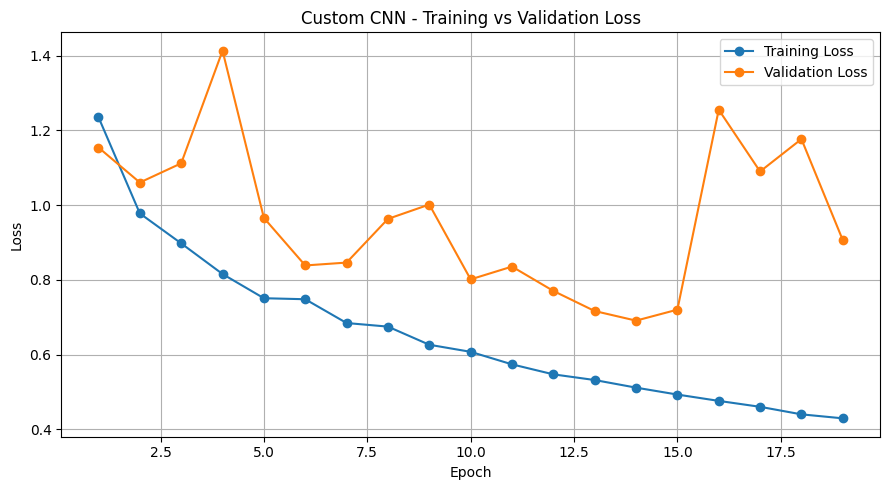

Loss graph saved successfully!


In [25]:
# ==========================================
# STEP 23: PLOT TRAINING AND VALIDATION LOSS
# ==========================================

plt.figure(figsize=(9, 5))

# Plot training loss across epochs
plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker='o',
    label='Training Loss'
)

# Plot validation loss across epochs
plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker='o',
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Custom CNN - Training vs Validation Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()

# Save graph in Google Drive
history_path = os.path.join(
    project_path, 'results', 'training_history'
)
os.makedirs(history_path, exist_ok=True)

plt.savefig(
    os.path.join(history_path, 'custom_cnn_loss.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Loss graph saved successfully!")

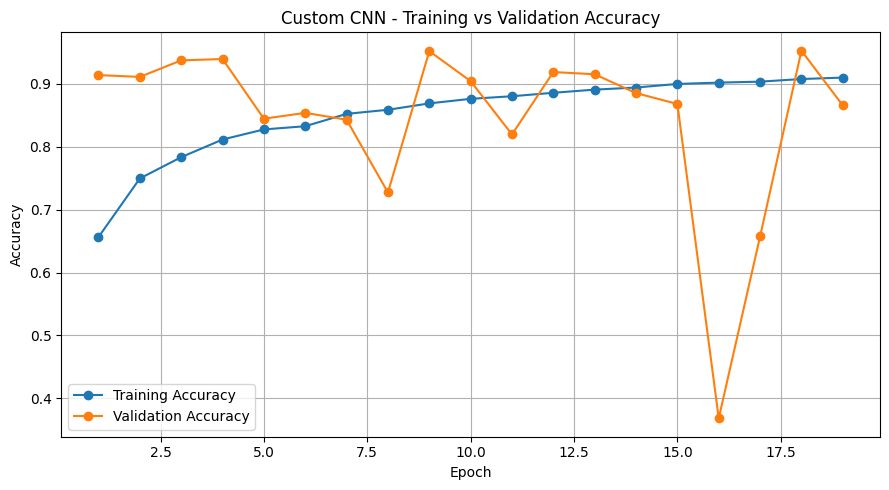

Accuracy graph saved successfully!


In [26]:
# ==========================================
# STEP 24: PLOT TRAINING AND VALIDATION ACCURACY
# ==========================================

plt.figure(figsize=(9, 5))

# Plot training accuracy
plt.plot(
    range(1, len(train_accuracies) + 1),
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)

# Plot validation accuracy
plt.plot(
    range(1, len(val_accuracies) + 1),
    val_accuracies,
    marker='o',
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Custom CNN - Training vs Validation Accuracy')

plt.legend()
plt.grid(True)
plt.tight_layout()

# Save graph in Google Drive
plt.savefig(
    os.path.join(history_path, 'custom_cnn_accuracy.png'),
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Accuracy graph saved successfully!")

In [28]:
# ==========================================
# STEP 25A: SET THE CORRECT CHECKPOINT PATH
# ==========================================

# Specify the complete path, including the model filename
checkpoint_path = (
    '/content/drive/MyDrive/Wafer Classification/'
    'checkpoints/custom_cnn.pth'
)

# Check whether the checkpoint file exists
import os

print("Checkpoint exists:", os.path.isfile(checkpoint_path))
print("Checkpoint path:", checkpoint_path)

Checkpoint exists: True
Checkpoint path: /content/drive/MyDrive/Wafer Classification/checkpoints/custom_cnn.pth


In [29]:
# ==========================================
# STEP 25B: LOAD THE BEST CUSTOM CNN MODEL
# ==========================================

# Load the saved model weights
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

# Apply the saved weights to our CNN
model.load_state_dict(checkpoint)

# Set model to evaluation mode
model.eval()

print("Best Custom CNN checkpoint loaded successfully!")
print("Model is ready for testing.")

Best Custom CNN checkpoint loaded successfully!
Model is ready for testing.


In [30]:
# ==========================================
# STEP 26: GENERATE TEST PREDICTIONS
# ==========================================

# Lists to store actual labels and model predictions
all_predictions = []
all_actual_labels = []

# Disable gradient calculations during testing
with torch.no_grad():

    for images, labels in test_loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Generate model predictions
        outputs = model(images)

        # Select the class with the highest score
        predictions = torch.argmax(outputs, dim=1)

        # Store predictions and actual labels
        all_predictions.extend(predictions.cpu().numpy())
        all_actual_labels.extend(labels.cpu().numpy())

# Convert lists into NumPy arrays
all_predictions = np.array(all_predictions)
all_actual_labels = np.array(all_actual_labels)

print("Testing completed!")
print("Total test samples:", len(all_actual_labels))
print("Total predictions:", len(all_predictions))

Testing completed!
Total test samples: 25855
Total predictions: 25855


In [31]:
# ==========================================
# STEP 27: EVALUATE CUSTOM CNN PERFORMANCE
# ==========================================

# Import evaluation metrics from scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate overall test accuracy
test_accuracy = accuracy_score(
    all_actual_labels,
    all_predictions
)

# Calculate macro-averaged precision
# Gives equal importance to all 9 classes
test_precision = precision_score(
    all_actual_labels,
    all_predictions,
    average='macro',
    zero_division=0
)

# Calculate macro-averaged recall
test_recall = recall_score(
    all_actual_labels,
    all_predictions,
    average='macro',
    zero_division=0
)

# Calculate macro-averaged F1-score
test_f1 = f1_score(
    all_actual_labels,
    all_predictions,
    average='macro',
    zero_division=0
)

# Display overall evaluation results
print("CUSTOM CNN - TEST RESULTS")
print("------------------------------")

print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall:    {test_recall:.4f}")
print(f"Macro F1-score:  {test_f1:.4f}")

# Display individual performance for each defect category
print("\nClassification Report:\n")

print(
    classification_report(
        all_actual_labels,
        all_predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

CUSTOM CNN - TEST RESULTS
------------------------------
Test Accuracy:  0.8859
Macro Precision: 0.5866
Macro Recall:    0.8227
Macro F1-score:  0.6579

Classification Report:

              precision    recall  f1-score   support

      Center       0.48      0.77      0.59       603
       Donut       0.56      0.84      0.68        83
    Edge-Loc       0.65      0.62      0.63       772
   Edge-Ring       0.95      0.97      0.96      1432
         Loc       0.23      0.69      0.34       576
   Near-full       0.50      0.87      0.63        15
      Random       0.70      0.95      0.81       131
     Scratch       0.21      0.80      0.33       177
        none       0.99      0.90      0.94     22066

    accuracy                           0.89     25855
   macro avg       0.59      0.82      0.66     25855
weighted avg       0.94      0.89      0.91     25855



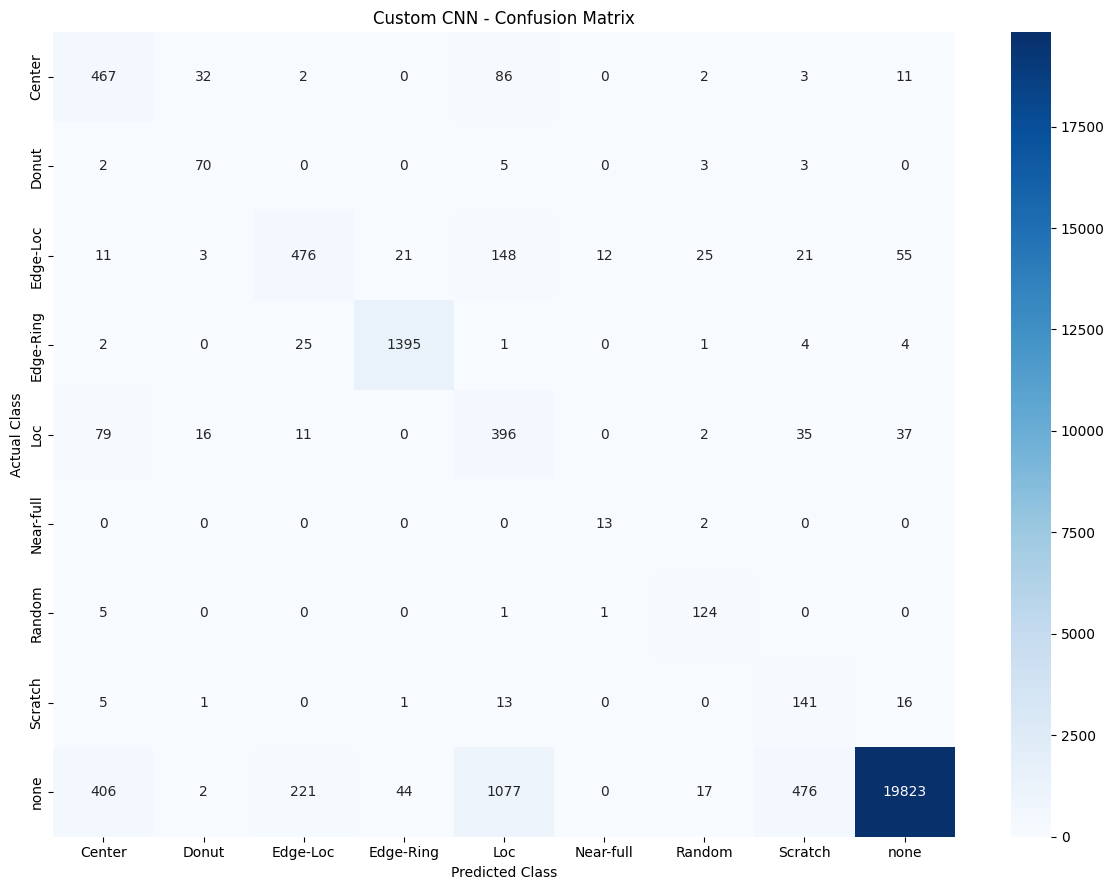

Confusion matrix saved successfully!


In [32]:
# ==========================================
# STEP 28: GENERATE CONFUSION MATRIX
# ==========================================

# Import required libraries
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(
    all_actual_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

# Plot the confusion matrix
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

# Save the confusion matrix in Google Drive
plt.savefig(
    "/content/drive/MyDrive/Wafer Classification/results/custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

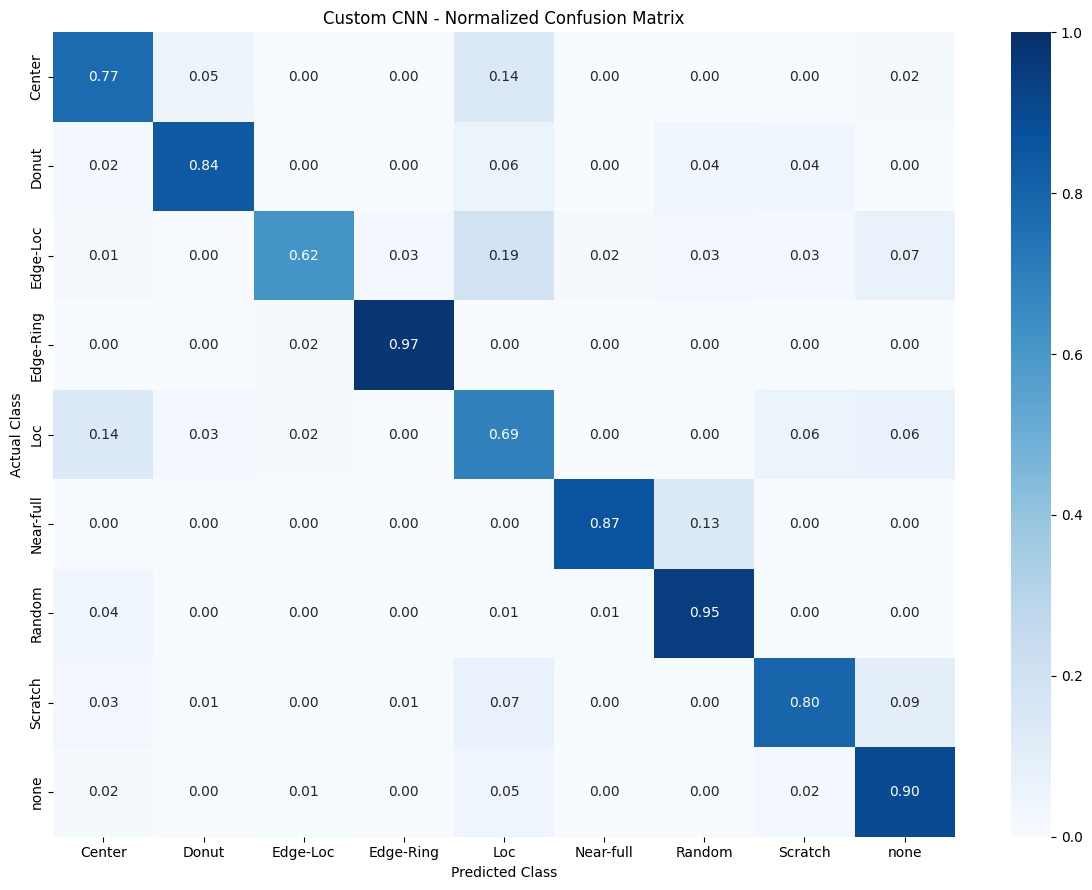

Normalized confusion matrix saved successfully!


In [33]:
# ==========================================
# STEP 29: NORMALIZED CONFUSION MATRIX
# ==========================================

# Import confusion matrix function
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Calculate normalized confusion matrix
# Each row is divided by its total number of actual samples
cm_normalized = confusion_matrix(
    all_actual_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    normalize='true'
)

# Create the plot
plt.figure(figsize=(12, 9))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    vmin=0,
    vmax=1
)

plt.title("Custom CNN - Normalized Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

# Save the normalized confusion matrix
plt.savefig(
    "/content/drive/MyDrive/Wafer Classification/results/custom_cnn_normalized_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Normalized confusion matrix saved successfully!")